# Question 2

## Setup

In [1]:
from pathlib import Path
import contextlib
import io
import time
import warnings

warnings.filterwarnings('ignore')

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# will use the same denosing function as Q1.1, kept in a shared module so the web app
# (Question 2.3) cleans user input in exactly the same way
import sys
sys.path.append('../deployment')
from preprocessing import clean_text  # shared with the web app

# Folder layout: notebooks/ (this folder), ../data, ../deployment; plots go to outputs/
DATA_DIR = Path('../data')
OUT_DIR = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

## Data preparation

In [2]:
df = pd.read_json(DATA_DIR / 'research_abstracts.json')
df = df.dropna(subset=['Abstract', 'Label'])
df = df.drop_duplicates(subset='Abstract').reset_index(drop=True)

df['cleaned_abstract'] = df['Abstract'].apply(clean_text)
df = df[df['cleaned_abstract'].str.strip() != ''].reset_index(drop=True)

X = df['cleaned_abstract']
y = df['Label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Training set: {len(X_train)} samples | Test set: {len(X_test)} samples")
print("Class balance (train):", y_train.value_counts().to_dict())

# 5-fold stratified cross-validation on the training set is used to compare
# models; the test set is only used once per final model.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training set: 900 samples | Test set: 225 samples
Class balance (train): {'classical': 712, 'ai': 188}


### Feature extractors and evaluation helper

In [3]:
def tfidf():
    """TF-IDF configuration that I selected in Question 1.2."""
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000,
                           sublinear_tf=True)


class Word2VecVectorizer(BaseEstimator, TransformerMixin):

    def __init__(self, vector_size=100, window=5, min_count=2, epochs=30, sg=0):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.epochs = epochs
        self.sg = sg

    def fit(self, X, y=None):
        sentences = [doc.split() for doc in X]
        # gensim's compiled BLAS routine prints a harmless "Exception ignored in
        # word2vec_inner.our_dot_float" message on some builds; it bypasses
        # sys.unraisablehook, so stderr is silenced only while Word2Vec trains
        with contextlib.redirect_stderr(io.StringIO()):
            self.model_ = Word2Vec(sentences, vector_size=self.vector_size,
                                   window=self.window, min_count=self.min_count,
                                   sg=self.sg, epochs=self.epochs,
                                   seed=RANDOM_STATE, workers=1)
        return self

    def transform(self, X):
        vectors = []
        for doc in X:
            words = [w for w in doc.split() if w in self.model_.wv.key_to_index]
            vectors.append(np.mean(self.model_.wv[words], axis=0) if words
                           else np.zeros(self.vector_size))
        return np.array(vectors)


def evaluate(name, pipe):
    """Cross-validate on the training set, then fit and score on the test set."""
    start = time.time()
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    return {
        'Model': name,
        'CV macro F1': cv_scores.mean(),
        'CV std': cv_scores.std(),
        'Test macro F1': f1_score(y_test, y_pred, average='macro'),
        'Test accuracy': accuracy_score(y_test, y_pred),
        'ai precision': precision_score(y_test, y_pred, pos_label='ai'),
        'ai recall': recall_score(y_test, y_pred, pos_label='ai'),
        'Time (s)': time.time() - start,
        'pipe': pipe,
        'y_pred': y_pred,
    }

## 2.1 Train at least four models and compare with the baseline

In [4]:
models_2_1 = {
    'Baseline: LogReg (Q1)': Pipeline([
        ('tfidf', tfidf()),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced',
                                   random_state=RANDOM_STATE)),
    ]),
    'Linear SVM': Pipeline([
        ('tfidf', tfidf()),
        ('clf', LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    'Complement Naive Bayes': Pipeline([
        ('tfidf', tfidf()),
        ('clf', ComplementNB()),
    ]),
    'Random Forest': Pipeline([
        ('tfidf', tfidf()),
        ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                       random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    'Gradient Boosting': Pipeline([
        ('tfidf', tfidf()),
        ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
    'Word2Vec + LogReg': Pipeline([
        ('w2v', Word2VecVectorizer()),
        ('scale', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced',
                                   random_state=RANDOM_STATE)),
    ]),
}

In [5]:
print("\n== QUESTION 2.1: MODEL COMPARISON ===")
results = []
for name, pipe in models_2_1.items():
    print(f"Training {name}...")
    results.append(evaluate(name, pipe))

results_df = (pd.DataFrame(results)
              .drop(columns=['pipe', 'y_pred'])
              .set_index('Model'))
print("\n", results_df.round(3))

baseline = results_df.loc['Baseline: LogReg (Q1)']
candidates = results_df.drop(index='Baseline: LogReg (Q1)')
beat_cv = candidates[candidates['CV macro F1'] > baseline['CV macro F1']].index.tolist()
beat_test = candidates[candidates['Test macro F1'] > baseline['Test macro F1']].index.tolist()
best_model_name = candidates['CV macro F1'].idxmax()

print(f"\nModels beating the baseline on CV macro F1:   {beat_cv}")
print(f"Models beating the baseline on test macro F1: {beat_test}")
print(f"Best model by CV macro F1: {best_model_name}")

best_result = next(r for r in results if r['Model'] == best_model_name)
print(f"\nTest-set classification report - {best_model_name}:")
print(classification_report(y_test, best_result['y_pred'], digits=3))


== QUESTION 2.1: MODEL COMPARISON ===
Training Baseline: LogReg (Q1)...


Training Linear SVM...


Training Complement Naive Bayes...


Training Random Forest...


Training Gradient Boosting...


Training Word2Vec + LogReg...



                         CV macro F1  CV std  Test macro F1  Test accuracy  ai precision  ai recall  Time (s)
Model                                                                                                       
Baseline: LogReg (Q1)         0.837   0.007          0.862          0.907         0.760      0.809     0.809
Linear SVM                    0.852   0.014          0.893          0.933         0.900      0.766     0.608
Complement Naive Bayes        0.811   0.031          0.798          0.884         0.839      0.553     0.483
Random Forest                 0.813   0.026          0.858          0.920         1.000      0.617     1.571
Gradient Boosting             0.847   0.028          0.861          0.911         0.814      0.745     5.091
Word2Vec + LogReg             0.788   0.030          0.790          0.849         0.610      0.766     9.338

Models beating the baseline on CV macro F1:   ['Linear SVM', 'Gradient Boosting']
Models beating the baseline on test macro F

### Model comparison chart

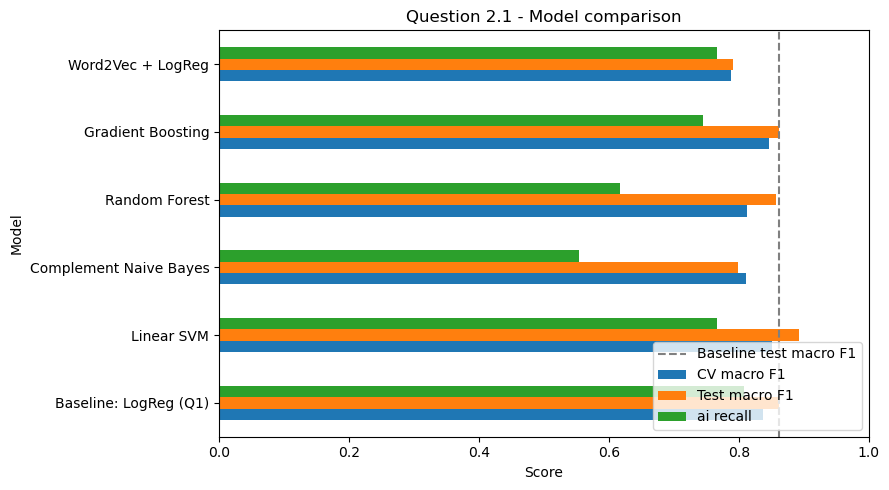

In [6]:
# Bar chart comparing all models
ax = results_df[['CV macro F1', 'Test macro F1', 'ai recall']].plot.barh(
    figsize=(9, 5), xlim=(0, 1))
ax.axvline(baseline['Test macro F1'], color='grey', linestyle='--',
           label='Baseline test macro F1')
ax.set_title('Question 2.1 - Model comparison')
ax.set_xlabel('Score')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q2_1_model_comparison.png', dpi=150)
plt.show()

## 2.2 Performance enhancement: hyperparameter tuning

In [7]:
param_grid_features = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2, 3],
    'tfidf__max_features': [3000, 5000, None],
}

tuning_setups = {
    'LogReg': (
        Pipeline([
            ('tfidf', TfidfVectorizer(sublinear_tf=True)),
            ('clf', LogisticRegression(max_iter=2000, class_weight='balanced',
                                       random_state=RANDOM_STATE)),
        ]),
        {**param_grid_features, 'clf__C': [0.3, 1, 3, 10, 30, 100]},
        'Baseline: LogReg (Q1)',
    ),
}
if best_model_name == 'Linear SVM':
    tuning_setups['Linear SVM'] = (
        Pipeline([
            ('tfidf', TfidfVectorizer(sublinear_tf=True)),
            ('clf', LinearSVC(class_weight='balanced', random_state=RANDOM_STATE,
                              max_iter=5000)),
        ]),
        {**param_grid_features, 'clf__C': [0.03, 0.1, 0.3, 1, 3, 10]},
        'Linear SVM',
    )

In [8]:
print("\n=== QUESTION 2.2: HYPERPARAMETER TUNING ===")
tuning_rows = []
tuned_preds = {}
tuned_searches = {}
for name, (pipe, grid, untuned_name) in tuning_setups.items():
    n_combos = np.prod([len(v) for v in grid.values()])
    print(f"\nTuning {name}: {n_combos} combinations x 5 folds = {n_combos * 5} fits...")
    search = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_searches[name] = search
    print("Best parameters:", search.best_params_)

    y_pred = search.predict(X_test)
    tuned_preds[name] = y_pred
    untuned = results_df.loc[untuned_name]
    for stage, cv_f1, test_f1, acc, rec, prec in [
        ('Before tuning', untuned['CV macro F1'], untuned['Test macro F1'],
         untuned['Test accuracy'], untuned['ai recall'], untuned['ai precision']),
        ('After tuning', search.best_score_, f1_score(y_test, y_pred, average='macro'),
         accuracy_score(y_test, y_pred), recall_score(y_test, y_pred, pos_label='ai'),
         precision_score(y_test, y_pred, pos_label='ai')),
    ]:
        tuning_rows.append({'Model': name, 'Stage': stage, 'CV macro F1': cv_f1,
                            'Test macro F1': test_f1, 'Test accuracy': acc,
                            'ai precision': prec, 'ai recall': rec})

    print(f"\nTest-set classification report - tuned {name}:")
    print(classification_report(y_test, y_pred, digits=3))

tuning_df = pd.DataFrame(tuning_rows).set_index(['Model', 'Stage'])
print("\n=== BEFORE TUNINg vs AFTER TUNING ===")
print(tuning_df.round(3))


=== QUESTION 2.2: HYPERPARAMETER TUNING ===

Tuning LogReg: 108 combinations x 5 folds = 540 fits...


Best parameters: {'clf__C': 30, 'tfidf__max_features': None, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 2)}

Test-set classification report - tuned LogReg:
              precision    recall  f1-score   support

          ai      0.878     0.766     0.818        47
   classical      0.940     0.972     0.956       178

    accuracy                          0.929       225
   macro avg      0.909     0.869     0.887       225
weighted avg      0.927     0.929     0.927       225


Tuning Linear SVM: 108 combinations x 5 folds = 540 fits...


Best parameters: {'clf__C': 3, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}

Test-set classification report - tuned Linear SVM:
              precision    recall  f1-score   support

          ai      0.897     0.745     0.814        47
   classical      0.935     0.978     0.956       178

    accuracy                          0.929       225
   macro avg      0.916     0.861     0.885       225
weighted avg      0.928     0.929     0.926       225


=== BEFORE TUNINg vs AFTER TUNING ===
                          CV macro F1  Test macro F1  Test accuracy  ai precision  ai recall
Model      Stage                                                                            
LogReg     Before tuning        0.837          0.862          0.907         0.760      0.809
           After tuning         0.866          0.887          0.929         0.878      0.766
Linear SVM Before tuning        0.852          0.893          0.933         0.900      0.766
       

### Confusion matrices: baseline before vs after tuning

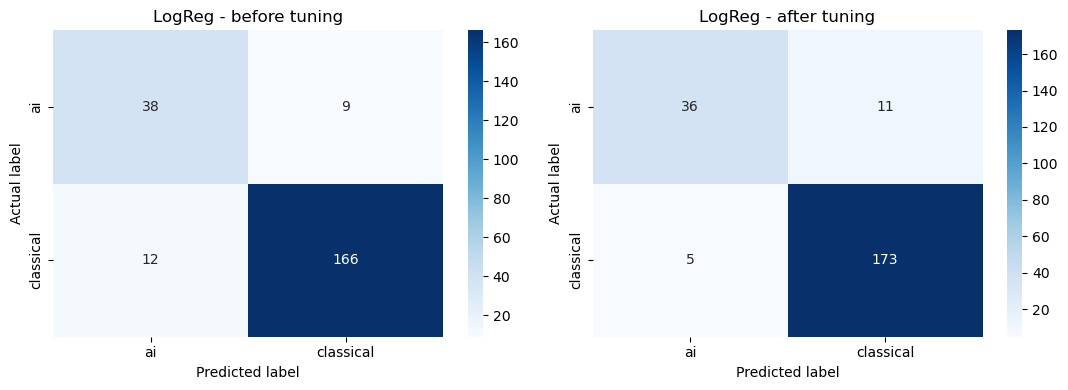

In [9]:
# Confusion matrices: baseline before tuning vs tuned baseline
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
baseline_pred = next(r for r in results if r['Model'] == 'Baseline: LogReg (Q1)')['y_pred']
for ax, (title, pred) in zip(axes, [('LogReg - before tuning', baseline_pred),
                                    ('LogReg - after tuning', tuned_preds['LogReg'])]):
    cm = confusion_matrix(y_test, pred, labels=['ai', 'classical'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['ai', 'classical'], yticklabels=['ai', 'classical'])
    ax.set_title(title)
    ax.set_ylabel('Actual label')
    ax.set_xlabel('Predicted label')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q2_2_tuning_confusion_matrices.png', dpi=150)
plt.show()

## 2.3 Save the best configuration for the web interface

In [10]:
candidates_all = {
    name: {'pipe': r['pipe'], 'cv_f1': r['CV macro F1'], 'test_f1': r['Test macro F1'],
           'test_acc': r['Test accuracy'], 'params': 'default settings'}
    for name, r in zip(results_df.index, results)
    if name != 'Word2Vec + LogReg'   # custom class; not needed, it ranks last
}
for name, search in tuned_searches.items():
    after = tuning_df.loc[(name, 'After tuning')]
    candidates_all[f'{name} (tuned)'] = {
        'pipe': search.best_estimator_, 'cv_f1': search.best_score_,
        'test_f1': after['Test macro F1'], 'test_acc': after['Test accuracy'],
        'params': search.best_params_,
    }

best_name = max(candidates_all, key=lambda n: candidates_all[n]['cv_f1'])
best = candidates_all[best_name]
print("\n=== QUESTION 2.3: BEST CONFIGURATION FOR DEPLOYMENT ===")
print(f"Selected: {best_name}  (CV macro F1 {best['cv_f1']:.3f}, "
      f"test macro F1 {best['test_f1']:.3f}, test accuracy {best['test_acc']:.3f})")
print("Parameters:", best['params'])

joblib.dump({
    'pipeline': best['pipe'],          # TF-IDF + classifier, fitted on the training set
    'model_name': best_name,
    'params': {k: str(v) for k, v in best['params'].items()}
              if isinstance(best['params'], dict) else best['params'],
    'cv_macro_f1': best['cv_f1'],
    'test_macro_f1': best['test_f1'],
    'test_accuracy': best['test_acc'],
    'n_train': len(X_train),
}, '../deployment/best_model.joblib')



=== QUESTION 2.3: BEST CONFIGURATION FOR DEPLOYMENT ===
Selected: LogReg (tuned)  (CV macro F1 0.866, test macro F1 0.887, test accuracy 0.929)
Parameters: {'clf__C': 30, 'tfidf__max_features': None, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 2)}


['../deployment/best_model.joblib']